<h1 style="text-align:center;color:black;background-color:#6C757D;padding:10px;border-radius:8px;font-size:28px;">Social Media Engagement Analytics</h1>

Task 1 — Data Import & Setup

Import CSV using Pandas


In [1]:
import pandas as pd


df = pd.read_csv('social_media_engagement_5000.csv')


df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


Check/convert data types

In [2]:
df.dtypes

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object

Convert date columns to datetime

In [3]:
df['posted_at'] = pd.to_datetime(df['posted_at'], format='%d-%m-%Y')
df['posted_at'].head()

0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[ns]

Use NumPy arrays for basic array operations

In [4]:
import numpy as np


Task 2 — Data Cleaning

In [5]:
missing_counts = df.isna().sum()
display(missing_counts[missing_counts > 0])

df_clean = df.copy()

for col in ['age', 'likes', 'comments', 'shares']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in ['gender', 'sentiment']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

display(df_clean.isna().sum().sum())

age          150
gender       150
likes        150
comments     150
shares       150
sentiment    150
dtype: int64

np.int64(0)

Duplicate Handling

In [6]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
4995    False
4996    False
4997    False
4998    False
4999    False
Length: 5000, dtype: bool

In [7]:
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

Total duplicate rows: 0


In [8]:
df_cleaned = df.drop_duplicates()
df.drop_duplicates(inplace=True)

In [9]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

Data Formatting

In [10]:
df_corrected = df_clean.copy()
gender= {
    'female': 'Female',
    'male': 'Male',
    'other': 'Other'
}
df_corrected['gender'] = (
    df_corrected['gender'].astype(str).str.strip().str.lower().map(gender)
    .fillna(df_corrected['gender'])
)
df_corrected['age'] = df_corrected['age'].round().astype('Int64')

for col in ['likes', 'comments', 'shares']:
    df_corrected[col] = (
        df_corrected[col]
        .clip(lower=0, upper=df_corrected['impression_count'])
        .round()
        .astype('int64')
    )

df_corrected.dtypes

user_id                      int64
age                          Int64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object

 Feature Cleaning

In [11]:
df_corrected['hashtag_count'] = (
    df_corrected['hashtags']
    .fillna('')
    .str.findall(r'#\w+')
    .str.len()
)

df_corrected[['hashtags', 'hashtag_count']].head()

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


In [12]:
sentiment_labels = {
    'positive': 'Positive',
    'neutral': 'Neutral',
    'negative': 'Negative'
}

sentiment = df_corrected['sentiment'].astype('string').str.strip().str.lower()
sentiment = sentiment.fillna(sentiment.mode().iat[0])

df_corrected['sentiment'] = sentiment.map(sentiment_labels).fillna(sentiment.str.title())

df_corrected['sentiment'].value_counts()

sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64

Task 3 — Data Exploration using Pandas

In [13]:
display(df.head())
display(df.tail())
display(df.shape)
display(df.columns)

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


(5000, 19)

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

Check data types and info with info() and dtypes.

In [14]:
display(df.info())
display(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               4850 non-null   float64       
 2   gender            4850 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             4850 non-null   float64       
 8   comments          4850 non-null   float64       
 9   shares            4850 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

None

user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object

Generate summary statistics using describe().

In [15]:
display(df.describe(include='all'))

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
count,5000.000000,4850.000000,4850,5000,5000.000000,5000,5000,4850.000000,4850.000000,4850.000000,5000.000000,5000.000000,5000,5000.000000,5000,5000,4850,5000,5000.000000
unique,NaN,NaN,3,10,NaN,4,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,3,3,761,NaN
top,NaN,NaN,Male,India,NaN,reel,fitness,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,mobile,positive,#tech,NaN
freq,NaN,NaN,1699,535,NaN,1283,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4517,1684,2363,201,NaN
mean,54561.890800,38.454021,NaN,NaN,548042.909000,NaN,NaN,10107.043711,1502.195670,1002.629485,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,NaN,NaN,NaN,NaN,0.964356
min,10055.000000,13.000000,NaN,NaN,100068.000000,NaN,NaN,10.000000,0.000000,0.000000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,NaN,NaN,NaN,NaN,0.006363
25%,32309.500000,26.000000,NaN,NaN,322543.500000,NaN,NaN,5068.500000,760.000000,498.000000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,NaN,NaN,NaN,NaN,0.145781
50%,54374.500000,38.000000,NaN,NaN,548077.500000,NaN,NaN,10105.500000,1497.000000,1012.000000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,NaN,NaN,NaN,NaN,0.253896
75%,77180.500000,51.000000,NaN,NaN,771574.500000,NaN,NaN,15115.000000,2256.000000,1501.000000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,NaN,NaN,NaN,NaN,0.504794
max,99963.000000,64.000000,NaN,NaN,999455.000000,NaN,NaN,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,NaN,NaN,NaN,NaN,191.504348


Analyze categorical distributions using value_counts(), 

unique(), and nunique().

In [16]:
categorical_cols = [
    'gender', 'country', 'post_type', 'post_category',
    'is_verified', 'device_type', 'sentiment'
]

for col in categorical_cols:
    print(f"\n{col} — value counts:")
    display(df_corrected[col].value_counts())

    print(f"{col} — unique values: {df_corrected[col].unique()}")
    print(f"{col} — number of unique values: {df_corrected[col].nunique()}")


gender — value counts:


gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64

gender — unique values: ['Female' 'Male' 'Other']
gender — number of unique values: 3

country — value counts:


country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64

country — unique values: ['Brazil' 'UK' 'France' 'Canada' 'Japan' 'Australia' 'India' 'UAE'
 'Germany' 'USA']
country — number of unique values: 10

post_type — value counts:


...

is_verified — unique values: [False  True]
is_verified — number of unique values: 2

device_type — value counts:


device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64

device_type — unique values: ['mobile' 'tablet' 'desktop']
device_type — number of unique values: 3

sentiment — value counts:


sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64

sentiment — unique values: ['Negative' 'Positive' 'Neutral']
sentiment — number of unique values: 3


Create a correlation matrix for numeric fields.

In [17]:
numeric_fields = df_corrected.select_dtypes(include='number')
correlation_matrix = numeric_fields.corr()
correlation_matrix.round(2)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.00,-0.01,0.02,0.03,-0.03,0.02,-0.02,0.02,0.01,-0.00,-0.01
age,-0.01,1.00,-0.01,-0.03,-0.01,0.01,0.01,0.01,-0.02,0.01,0.01
post_id,0.02,-0.01,1.00,0.01,-0.01,0.00,0.02,-0.01,-0.00,0.01,0.01
likes,0.03,-0.03,0.01,1.00,0.01,0.02,0.00,0.19,-0.03,-0.15,-0.00
comments,-0.03,-0.01,-0.01,0.01,1.00,0.02,-0.02,0.02,-0.01,-0.10,-0.01
shares,0.02,0.01,0.00,0.02,0.02,1.00,0.02,0.02,-0.01,-0.08,0.01
watch_time_sec,-0.02,0.01,0.02,0.00,-0.02,0.02,1.00,-0.00,0.00,-0.00,-0.02
impression_count,0.02,0.01,-0.01,0.19,0.02,0.02,-0.00,1.00,-0.02,-0.23,-0.00
follower_count,0.01,-0.02,-0.00,-0.03,-0.01,-0.01,0.00,-0.02,1.00,0.00,0.01
engagement_rate,-0.00,0.01,0.01,-0.15,-0.10,-0.08,-0.00,-0.23,0.00,1.00,0.01


Use groupby() to summarize metrics (e.g., avg likes by post 

type, impressions by country)

In [18]:
post_type_summary = (
    df_corrected.groupby('post_type')
    .agg(
        avg_likes=('likes', 'mean'),
        avg_comments=('comments', 'mean'),
        avg_shares=('shares', 'mean'),
        avg_engagement_rate=('engagement_rate', 'mean')
    )
    .round(2)
    .sort_values('avg_likes', ascending=False)
)

country_summary = (
    df_corrected.groupby('country')
    .agg(
        total_impressions=('impression_count', 'sum'),
        avg_impressions=('impression_count', 'mean')
    )
    .round(2)
    .sort_values('total_impressions', ascending=False)
)

display(post_type_summary)
display(country_summary)

,avg_likes,avg_comments,avg_shares,avg_engagement_rate
post_type,,,,
reel,9513.74,1494.95,977.08,0.78
video,9451.91,1462.91,990.51,1.12
image,9447.68,1513.93,1012.97,0.90
text,9415.88,1484.95,1002.25,1.06


,total_impressions,avg_impressions
country,,
India,28067377,52462.39
USA,25683200,51263.87
France,25656926,51727.67
UK,25201861,51119.39
Canada,24984716,48703.15
Brazil,24793360,49193.17
UAE,24610992,48928.41
Australia,23834767,48346.38
Germany,23816649,48605.41


Task 4 — Data Wrangling 

Use merge, concat, or join if combining DataFrames.

In [19]:
post_type_counts = (
    df_corrected['post_type'].value_counts().rename('post_count').rename_axis('post_type').reset_index()
)
post_type_combined = (
    post_type_summary.reset_index().merge(post_type_counts, on='post_type', how='left')
)
display(post_type_combined)
combined_summaries = pd.concat(
    {
        'post_type': post_type_combined.set_index('post_type'),
        'country': country_summary
    },
    axis=0
)
display(combined_summaries)

,post_type,avg_likes,avg_comments,avg_shares,avg_engagement_rate,post_count
0,reel,9513.74,1494.95,977.08,0.78,1283
1,video,9451.91,1462.91,990.51,1.12,1225
2,image,9447.68,1513.93,1012.97,0.90,1247
3,text,9415.88,1484.95,1002.25,1.06,1245


avg_likes  avg_comments  avg_shares  avg_engagement_rate  \
post_type reel         9513.74       1494.95      977.08                 0.78   
          video        9451.91       1462.91      990.51                 1.12   
          image        9447.68       1513.93     1012.97                 0.90   
          text         9415.88       1484.95     1002.25                 1.06   
country   India            NaN           NaN         NaN                  NaN   
          USA              NaN           NaN         NaN                  NaN   
          France           NaN           NaN         NaN                  NaN   
          UK               NaN           NaN         NaN                  NaN   
          Canada           NaN           NaN         NaN                  NaN   
          Brazil           NaN           NaN         NaN                  NaN   
          UAE              NaN           NaN         NaN                  NaN   
          Australia        NaN           NaN         NaN                  NaN   
          Germany          NaN           NaN         NaN                  NaN   
          Japan            NaN           NaN         NaN                  NaN   

                     post_count  total_impressions  avg_impressions  
post_type reel           1283.0                NaN              NaN  
          video          1225.0                NaN              NaN  
          image          1247.0                NaN              NaN  
          text           1245.0                NaN              NaN  
country   India             NaN         28067377.0         52462.39  
          USA               NaN         25683200.0         51263.87  
          France            NaN         25656926.0         51727.67  
          UK                NaN         25201861.0         51119.39  
          Canada            NaN         24984716.0         48703.15  
          Brazil            NaN         24793360.0         49193.17  
          UAE               NaN         24610992.0         48928.41  
          Australia         NaN         23834767.0         48346.38  
          Germany           NaN         23816649.0         48605.41  
          Japan             NaN         23418816.0         49616.14

Create new fields such as engagement_score, log-transformed

 metrics (optional), and hashtag_count.

In [20]:
df_corrected['engagement_score'] = (df_corrected['likes']+ df_corrected['comments']+ df_corrected['shares']
)

for col in ['likes', 'comments', 'shares', 'impression_count', 'follower_count']:
    df_corrected[f'log_{col}'] = np.log1p(df_corrected[col])

display(df_corrected[
    ['engagement_score', 'hashtag_count', 'log_likes', 'log_comments',
     'log_shares', 'log_impression_count', 'log_follower_count']].head())

,engagement_score,hashtag_count,log_likes,log_comments,log_shares,log_impression_count,log_follower_count
0,8522,3,8.855378,5.872118,7.054450,10.706632,11.311238
1,16163,1,9.371694,7.865955,7.499977,11.292491,8.693497
2,6161,1,8.489411,5.843544,6.862758,10.711280,13.125925
3,7482,3,8.585039,6.988413,6.956545,11.162744,13.081985
4,10054,1,8.702843,7.914252,7.170888,8.702843,12.858234


Task 5 — Statistical Analysis 

In [21]:
stats_columns = {
    'likes': 'likes',
    'comments': 'comments',
    'shares': 'shares',
    'watch_time': 'watch_time_sec',
    'engagement_rate': 'engagement_rate'
}

descriptive_stats = pd.DataFrame({
    name: {
        'mean': df_corrected[column].mean(),
        'median': df_corrected[column].median(),
        'mode': df_corrected[column].mode().tolist(),
        'standard_deviation': df_corrected[column].std(),
        'variance': df_corrected[column].var(),
        '25th_percentile': df_corrected[column].quantile(0.25),
        '50th_percentile': df_corrected[column].quantile(0.50),
        '75th_percentile': df_corrected[column].quantile(0.75),
        'skewness': df_corrected[column].skew(),
        'kurtosis': df_corrected[column].kurt()
    }
    for name, column in stats_columns.items()
}).T

display(descriptive_stats.round(3))

,mean,median,mode,standard_deviation,variance,25th_percentile,50th_percentile,75th_percentile,skewness,kurtosis
likes,9457.7472,9382.0,[10106],5667.387663,32119282.917076,4561.25,9382.0,14155.75,0.119666,-1.124048
comments,1489.3434,1497.0,[1497],857.357127,735061.243725,765.0,1497.0,2227.25,0.019633,-1.149424
shares,995.5904,1012.0,[1012],570.213323,325143.233274,501.0,1012.0,1470.0,-0.001774,-1.149098
watch_time,4014.5032,4034.5,"[916, 2145, 4360, 7003, 7688]",2308.096459,5327309.264243,2017.75,4034.5,6020.25,-0.018196,-1.195652
engagement_rate,0.964356,0.253896,"[0.006362909, 0.007420223, 0.012675682, 0.0126...",5.318029,28.281435,0.145781,0.253896,0.504794,18.781271,482.991739


Task 6 — Data Visualization

Matplotlib


Scatter


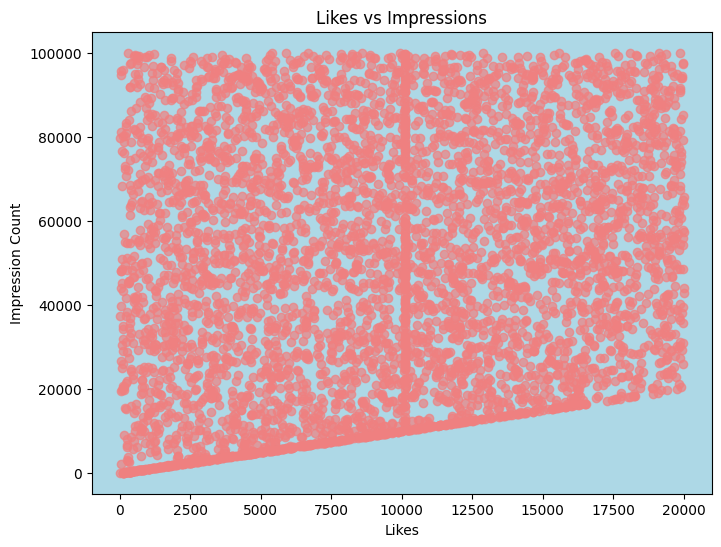

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(df_corrected['likes'], df_corrected['impression_count'],linestyle= '-', color='lightcoral', alpha=0.7)
plt.gca().set_facecolor("lightblue")
plt.title('Likes vs Impressions')
plt.xlabel('Likes')
plt.ylabel('Impression Count')
plt.show()




Line plot: 

In [23]:
df_corrected.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count', 'engagement_score', 'log_likes', 'log_comments',
       'log_shares', 'log_impression_count', 'log_follower_count'],
      dtype='object')

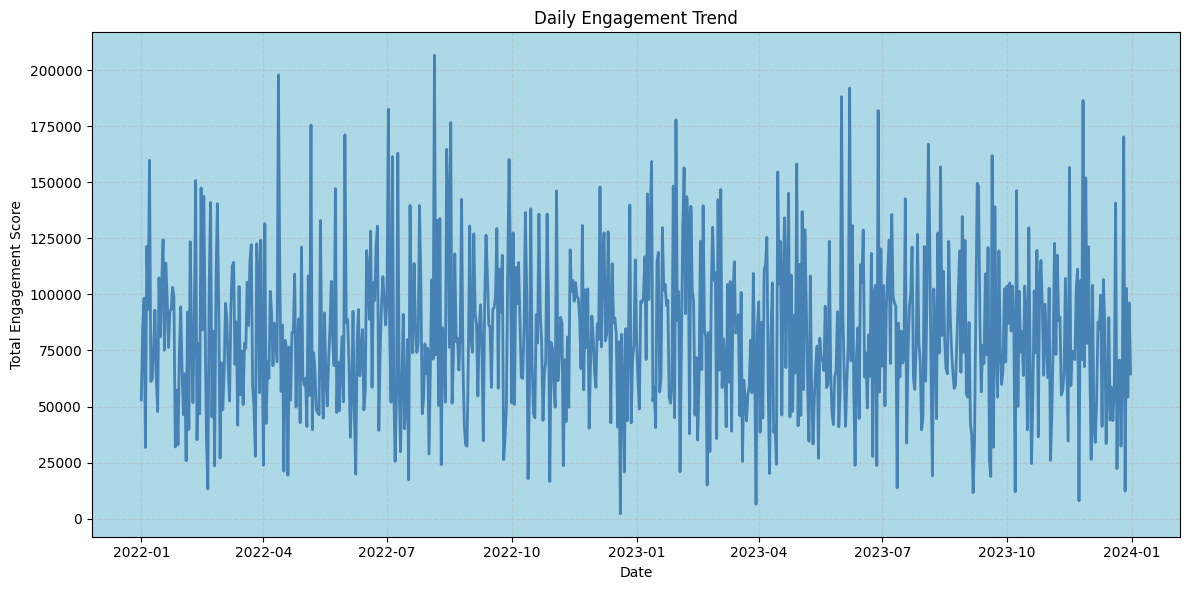

In [24]:
daily_engagement = (df_corrected.groupby(df_corrected['posted_at'].dt.floor('D'))['engagement_score'].sum().sort_index())

plt.figure(figsize=(12, 6))
plt.plot(daily_engagement.index, daily_engagement.values, color='steelblue', linewidth=2)
plt.title('Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Total Engagement Score')
plt.gca().set_facecolor("lightblue")
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Bar plot:

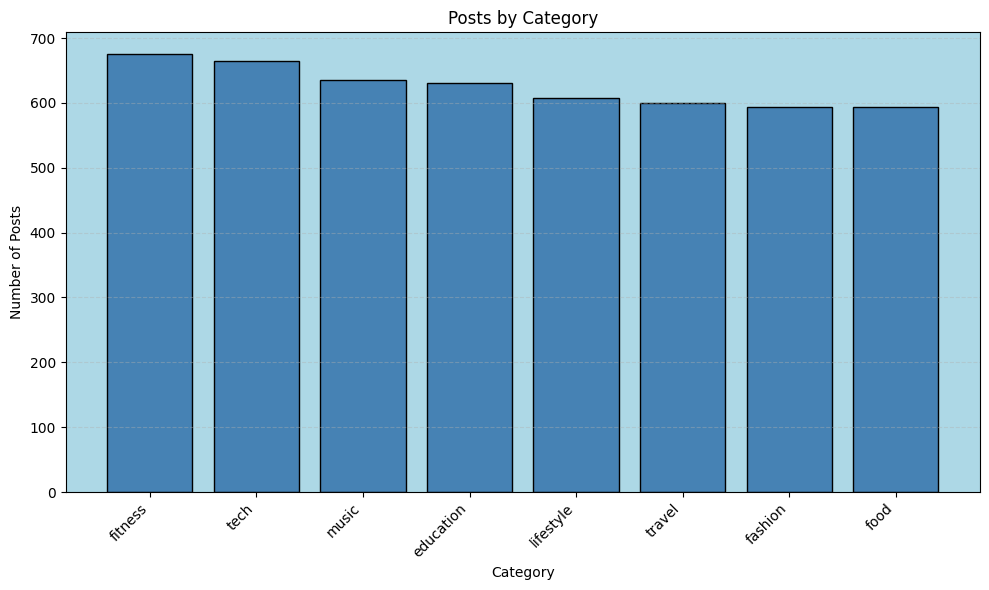

In [25]:
post_category_counts = df_corrected['post_category'].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
bars = plt.bar(post_category_counts.index, post_category_counts.values, color='steelblue', edgecolor='black')
plt.title('Posts by Category')
plt.xlabel('Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45, ha='right')
plt.gca().set_facecolor("lightblue")
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Pie plot:

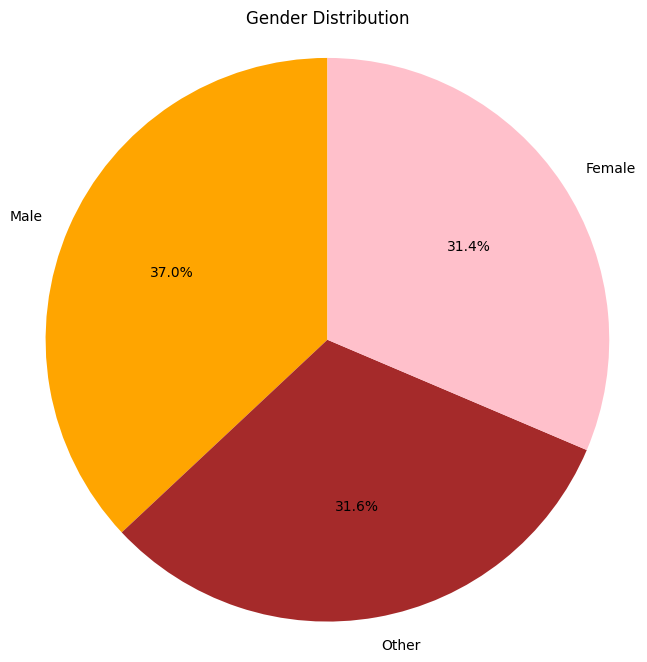

In [26]:
gender_counts = df_corrected['gender'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['orange', 'brown', 'pink']
)
plt.title('Gender Distribution')
plt.axis('equal')
plt.show()

Histogram:

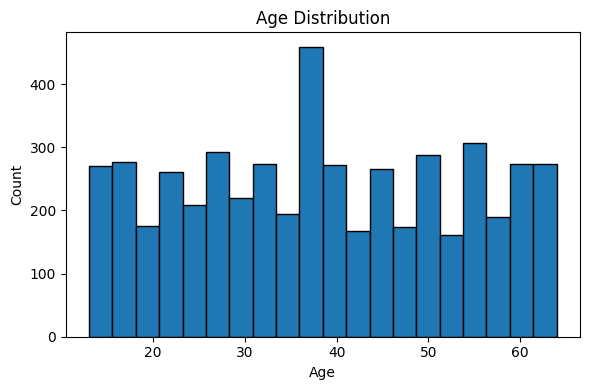

In [27]:
plt.figure(figsize=(6, 4))
plt.hist(df_corrected['age'].dropna().astype(float), bins=20, edgecolor='black')
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Box plot

In [28]:
df_corrected.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count', 'engagement_score', 'log_likes', 'log_comments',
       'log_shares', 'log_impression_count', 'log_follower_count'],
      dtype='object')

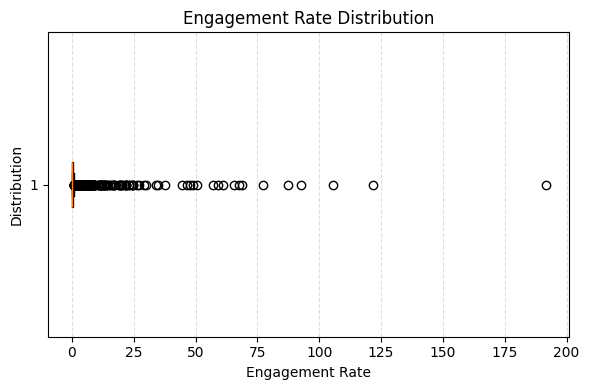

In [29]:
plt.figure(figsize=(6, 4))
plt.boxplot(df_corrected['engagement_rate'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title("Engagement Rate Distribution")
plt.xlabel("Engagement Rate")
plt.ylabel("Distribution")
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Seaborn

Count plot

In [30]:
import seaborn as sns

C:\Users\hp\AppData\Local\Temp\ipykernel_5704\1772045258.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='post_type', data=df_corrected, palette='pastel')


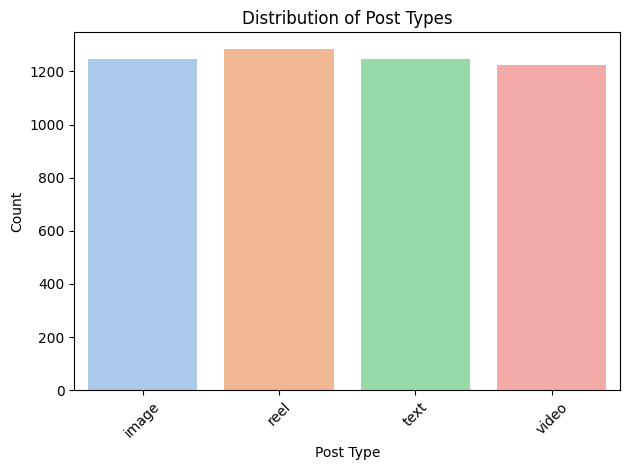

In [31]:
sns.countplot(x='post_type', data=df_corrected, palette='pastel')
plt.title('Distribution of Post Types')
plt.xlabel('Post Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Bar plot

C:\Users\hp\AppData\Local\Temp\ipykernel_5704\350174154.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='post_category', y='engagement_score', data=df_corrected, palette='muted')


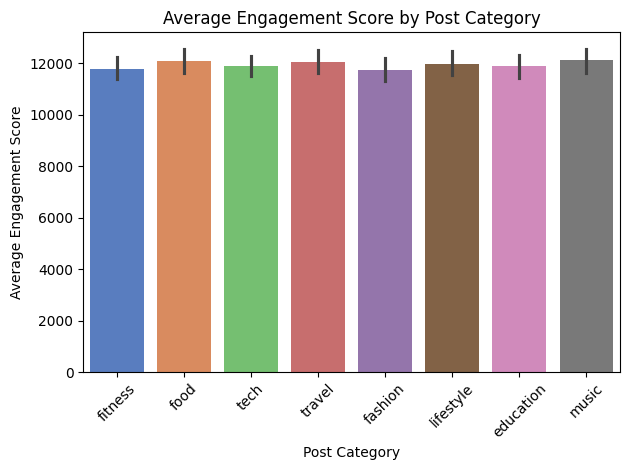

In [32]:
sns.barplot(x='post_category', y='engagement_score', data=df_corrected, palette='muted')
plt.title('Average Engagement Score by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Engagement Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

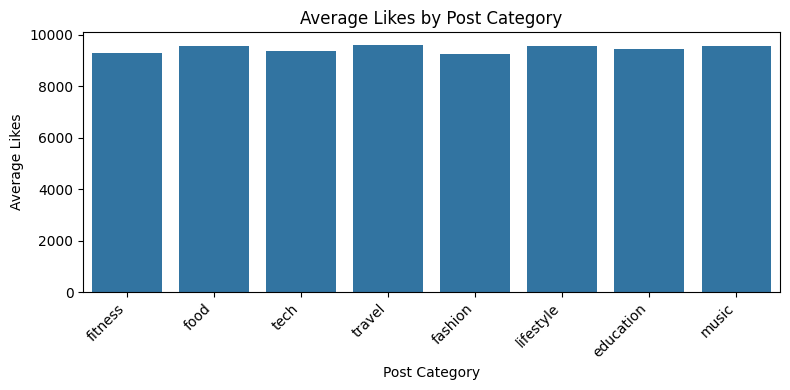

In [33]:
plt.figure(figsize=(8, 4))
sns.barplot(x="post_category", y="likes", data=df_corrected, errorbar=None)
plt.title("Average Likes by Post Category")
plt.xlabel("Post Category")
plt.ylabel("Average Likes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Violin plot

C:\Users\hp\AppData\Local\Temp\ipykernel_5704\159107886.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='sentiment',y='follower_count',data=df_corrected,palette='coolwarm',order=['Negative', 'Neutral', 'Positive'],inner='quartile')


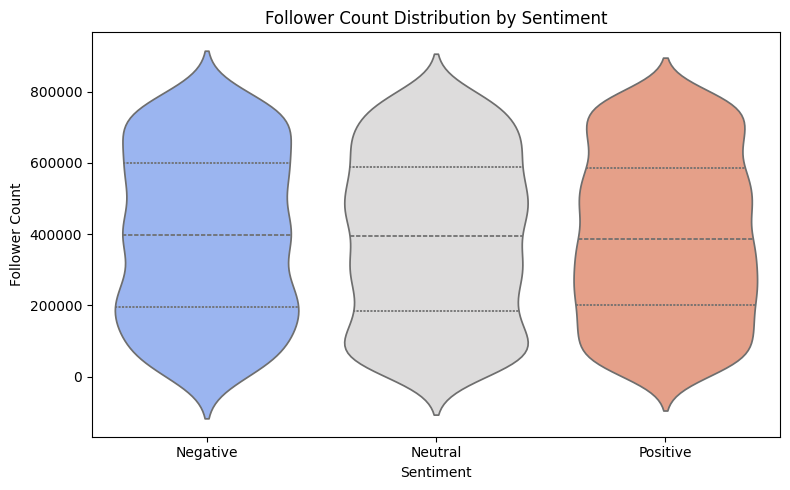

In [34]:
plt.figure(figsize=(8, 5))
sns.violinplot(x='sentiment',y='follower_count',data=df_corrected,palette='coolwarm',order=['Negative', 'Neutral', 'Positive'],inner='quartile')
plt.title('Follower Count Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.tight_layout()
plt.show()

Pair plot

<Figure size 600x400 with 0 Axes>

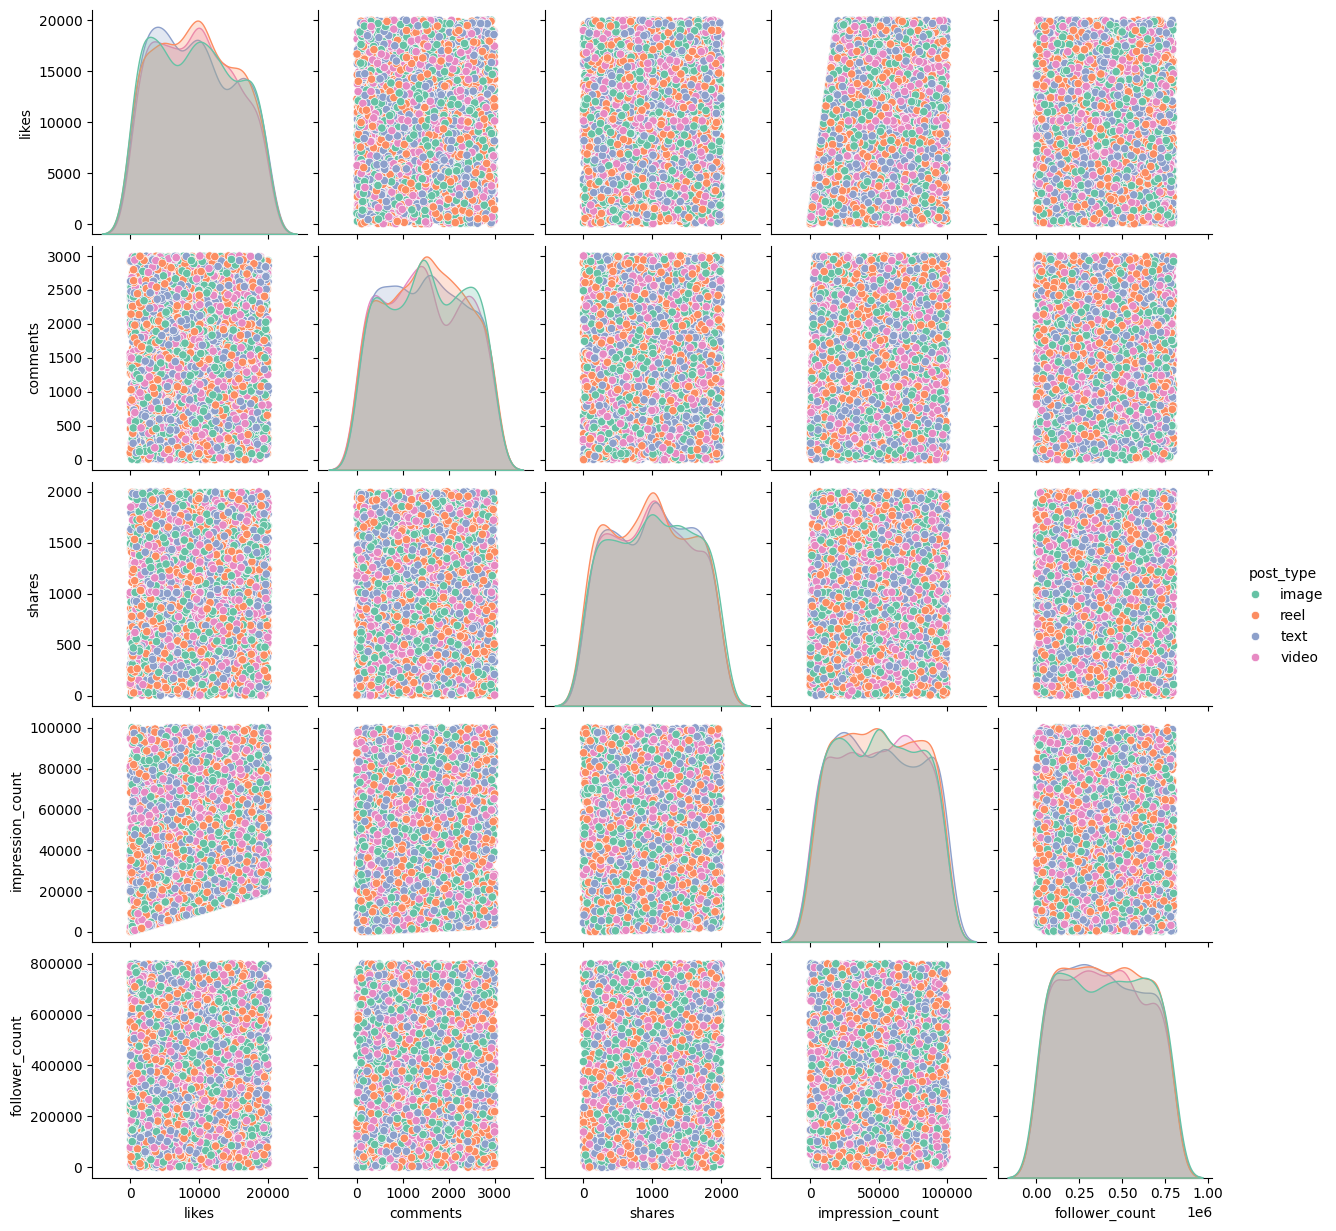

In [35]:
plt.figure(figsize=(6, 4))
sns.pairplot(data=df_corrected, vars=['likes', 'comments', 'shares', 'impression_count', 'follower_count'], hue='post_type', palette='Set2')
plt.show()

Heatmap

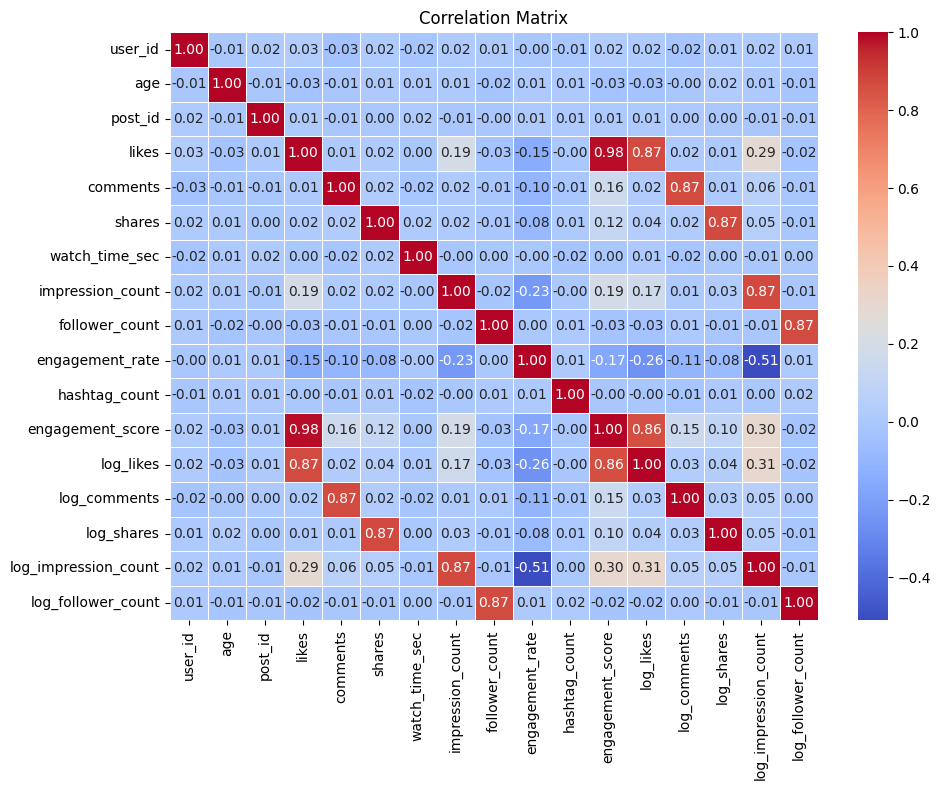

In [36]:
plt.figure(figsize=(10, 8))
numeric_df = df_corrected.select_dtypes(include=["number"])

sns.heatmap(numeric_df.corr(),annot=True,fmt=".2f",cmap="coolwarm",linewidths=0.5,cbar=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


Swarm plot:

C:\Users\hp\AppData\Local\Temp\ipykernel_5704\1987653464.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(x='device_type', y='engagement_score', data=df_corrected, palette='Set1')
c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\categorical.py:3399: UserWarning: 48.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\categorical.py:3399: UserWarning: 47.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\categorical.py:3399: UserWarning: 59.1% of the points cannot be placed; you may want

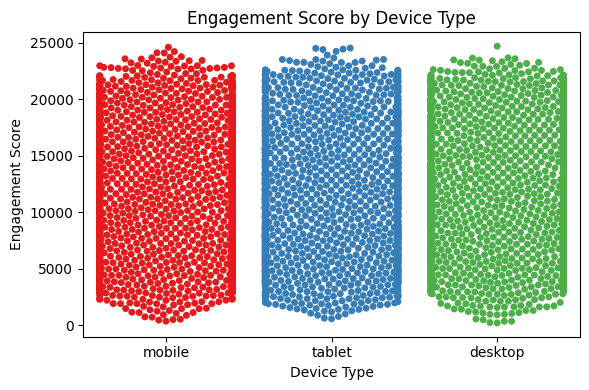

In [37]:
plt.figure(figsize=(6, 4))
sns.swarmplot(x='device_type', y='engagement_score', data=df_corrected, palette='Set1')
plt.title("Engagement Score by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Engagement Score")
plt.tight_layout()
plt.show()


In [38]:
df_corrected


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,log_likes,log_comments,log_shares,log_impression_count,log_follower_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,...,Negative,#foodie #travel #love,0.190862,3,8522,8.855378,5.872118,7.054450,10.706632,11.311238
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,...,Negative,#fitness,0.201493,1,16163,9.371694,7.865955,7.499977,11.292491,8.693497
2,86820,32,Female,UK,109864,text,food,4862,344,955,...,Positive,#foodie,0.137345,1,6161,8.489411,5.843544,6.862758,10.711280,13.125925
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,...,Negative,#music #foodie #fun,0.106195,3,7482,8.585039,6.988413,6.956545,11.162744,13.081985
4,16265,34,Other,UK,449706,image,fitness,6019,2735,1300,...,Negative,#travel,2.777372,1,10054,8.702843,7.914252,7.170888,8.702843,12.858234
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,...,Positive,#travel #fun,0.466761,2,20060,9.693445,7.607878,7.516433,10.668444,13.378784
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,...,Negative,#foodie #reels,0.621155,2,21241,9.736547,7.913887,7.367709,10.439893,13.278690
4997,67021,63,Female,USA,273595,text,travel,13487,1497,167,...,Positive,#lifestyle #tech,0.679688,2,15151,9.509556,7.311886,5.123964,10.072428,13.088912
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,...,Positive,#reels #love #fitness,0.223518,3,19896,9.734773,7.162397,7.446585,11.396549,12.118858


Plotly (Interactive)

In [39]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\hp\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [40]:
df_corrected.columns


Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count', 'engagement_score', 'log_likes', 'log_comments',
       'log_shares', 'log_impression_count', 'log_follower_count'],
      dtype='object')

plotly line chart

In [41]:
data = df_corrected.groupby("post_category")["engagement_score"].sum().reset_index()
data

,post_category,engagement_score
0,education,7504419
1,fashion,6978870
2,fitness,7961357
3,food,7156907
4,lifestyle,7274009
5,music,7703918
6,tech,7897780
7,travel,7236145


In [42]:
import plotly.express as px
data = df_corrected.groupby("post_category")["engagement_score"].sum().reset_index()

fig = px.line(
    data,
    x="post_category",
    y="engagement_score",
    markers=True,
    title="Total Engagement by Post Category"
  
)

fig.show()


plotly bar chart

In [43]:
bar_chart = (
    df_corrected.groupby("country", as_index=False)["engagement_rate"]
    .mean()
    .rename(columns={"engagement_rate": "average_engagement"})
    .sort_values("average_engagement", ascending=False)
)

fig = px.bar(
    bar_chart,
    x="country",
    y="average_engagement",
    title="Average Engagement Rate by Country",
    labels={"average_engagement": "Avg Engagement Rate", "country": "Country"},
    color="average_engagement",
)

fig.show()

In [44]:
df_corrected.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count', 'engagement_score', 'log_likes', 'log_comments',
       'log_shares', 'log_impression_count', 'log_follower_count'],
      dtype='object')

plotly bubble chart

In [45]:
fig = px.scatter(
    df_corrected,
    x="age",
    y="engagement_rate",
    size="follower_count",
    color="post_category",
    hover_name="post_type",
    title="Engagement Rate vs Age by Post Category"
)
fig.show()


Final Conclusion

Content Performance

Based on the analysis, posts in the food and fitness category achieved the highest overall engagement rate.

The analysis reveals that food content stands out as the best-performing category

Brazil secured the highest average engagement rate among all analyzed countries

User Trends

The platform's primary audience is concentrated in the 30-to-40 age, identifying this mature demographic as the largest user segment.

Verified accounts maintain highly consistent visibility, spreading wide across the entire impression spectrum (up to 100k) rather than being 
restricted to a small number of viral posts.

Behavioral Insights

Content visibility peaks during midday and early evening intervals

User engagement is highly uniform across all devices Mobile, Tablet, and Desktop

Sentiment Analysis

Content sentiment performs uniformly regardless 

Negative and neutral sentiment posts show no structural restriction or bias based on account size